# Human vs. Animal Fight – Visualisierungstechniken aus der Vorlesung

**Datensatz:** YouGov-Umfrage (12.–13. April 2021, n = 1.224 US-Erwachsene):
*„Welche dieser Tiere könntest du unbewaffnet in einem Kampf besiegen?“* –
15 Tiere × 10 Gruppen (Gesamt, Geschlecht, 3 Altersgruppen, 4 US-Regionen) ×
3 Antwortanteile (kann besiegen / kann nicht besiegen / weiß nicht).

Der Datensatz ist **multivariat** (je Tier 9 Teilgruppenwerte + 3 Antwortanteile),
hat eine **räumliche** Komponente (US-Regionen) und eine **geordnete**
Dimension (Altersgruppen). Jede Visualisierung unten ist einer Technik aus dem
Foliensatz *IVI3 – Visualization Techniques* zugeordnet (Folie in Klammern).

| # | Technik (Folie) | Frage an die Daten |
|---|---|---|
| 0 | Gestapeltes Balkendiagramm (Basis) | Wie verteilen sich die Antworten je Tier? |
| 1 | Tabellenbasiert – Heatmap (5) | Wie zuversichtlich ist jede Teilgruppe bei jedem Tier? |
| 2 | Achsenbasiert – Streudiagramm (6) | Wie groß ist der Unterschied Männer vs. Frauen? |
| 3 | Kombiniert bivariat – SPLOM (9) | Welche Kennzahlen hängen zusammen? |
| 4 | Polyline – Parallele Koordinaten (10–12) | Wie verlaufen die Tierprofile über alle Teilgruppen? |
| 5 | Radar-Chart (13) | Gesamtprofil nach Geschlecht und Alter |
| 6 | Glyphen – Star Plot im Raster (19, 21) | Welche Tiere haben ein ähnliches Profil? |
| 7 | Dimensionsreduktion + Glyph-Platzierung (7, 21) | Ähnlichkeit als Nähe |
| 8 | Verschachtelt – Mosaik-Plot (25) | Antwortverteilung nach Altersgruppe inkl. Gruppengröße |
| 9 | Parallel Sets / Alluvial (14) | Fluss von Altersgruppe zu Antwort |
| 10 | Räumlich – Grid-Kartogramm (59) | Gibt es regionale Unterschiede? |
| 11 | Slope Chart (77) | Männer → Frauen je Tier |
| 12 | Small Multiples (70) | Alterstrend je Tier |

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from adjustText import adjust_text
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import PathPatch, Polygon, Rectangle
from matplotlib.path import Path
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# --- Farben & Stil (validierte Referenzpalette, einheitlich in allen Charts) ---
INK, INK2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'   # kategoriale Slots 1–3 (CVD-sicher, alle Paare)
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'savefig.facecolor': SURFACE, 'font.family': 'sans-serif',
    'font.sans-serif': ['Segoe UI', 'DejaVu Sans'], 'font.size': 10,
    'text.color': INK, 'axes.labelcolor': INK2, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2, 'axes.edgecolor': AXIS,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlesize': 12,
    'axes.titleweight': 'semibold', 'axes.titlelocation': 'left', 'legend.frameon': False,
    'grid.color': GRID, 'grid.linewidth': 0.8,
})

RESP = ['could_beat_pct', 'could_not_beat_pct', 'dont_know_pct']
RESP_LABEL = {'could_beat_pct': 'Kann besiegen', 'could_not_beat_pct': 'Kann nicht besiegen',
              'dont_know_pct': 'Weiß nicht'}
RESP_COL = {'could_beat_pct': BLUE, 'could_not_beat_pct': ORANGE, 'dont_know_pct': AXIS}

SEQ = ['#cde2fb', '#b7d3f6', '#9ec5f4', '#86b6ef', '#6da7ec', '#5598e7', '#3987e5',
       '#2a78d6', '#256abf', '#1c5cab', '#184f95', '#104281', '#0d366b']
CMAP_SEQ = LinearSegmentedColormap.from_list('seq_blue', SEQ)
# divergierend: rot (weniger zuversichtlich) – grau – blau (zuversichtlicher)
CMAP_DIV = LinearSegmentedColormap.from_list('div', ['#a8302f', '#e66767', '#f0efec', '#3987e5', '#104281'])
AGE_COL = {'18-34': '#86b6ef', '35-54': '#2a78d6', '55+': '#104281'}   # ordinal: hell → dunkel

# --- Daten ---
df = pd.read_csv('yougov_humans_vs_animals_us_2021.csv')
DE = df.drop_duplicates('animal').set_index('animal')['animal_de']
total = df[df['group'] == 'Total'].set_index('animal')
ORDER = total.sort_values('could_beat_pct', ascending=False).index.tolist()

GENDER, AGE, REGION = ['Male', 'Female'], ['18-34', '35-54', '55+'], ['Northeast', 'Midwest', 'South', 'West']
GROUPS = GENDER + AGE + REGION
GROUP_DE = {'Total': 'Gesamt', 'Male': 'Männer', 'Female': 'Frauen', '18-34': '18–34',
            '35-54': '35–54', '55+': '55+', 'Northeast': 'Nordosten',
            'Midwest': 'Mittl. Westen', 'South': 'Süden', 'West': 'Westen'}
beat = df.pivot(index='animal', columns='group', values='could_beat_pct').loc[ORDER]
total = total.loc[ORDER]

# Archetypen (identisch mit den k-Means-Clustern aus exploration.ipynb)
def archetype(p):
    return 'Sichere Siege' if p >= 50 else ('Raubtiere' if p <= 12 else 'Unsicheres Mittelfeld')
ARCH_ORDER = ['Sichere Siege', 'Unsicheres Mittelfeld', 'Raubtiere']
ARCH_COL = {'Sichere Siege': AQUA, 'Unsicheres Mittelfeld': BLUE, 'Raubtiere': ORANGE}
arch = total['could_beat_pct'].map(archetype)
acol = arch.map(ARCH_COL)

# Abgeleitete Kennzahlen je Tier (für SPLOM, Glyphen, PCA)
feat = pd.DataFrame({
    'Kann besiegen (%)': total['could_beat_pct'],
    'Weiß nicht (%)': total['dont_know_pct'],
    'Gender-Gap (pp)': beat['Male'] - beat['Female'],
    'Alters-Gap (pp)': beat['18-34'] - beat['55+'],
    'Regions-Spanne (pp)': beat[REGION].max(axis=1) - beat[REGION].min(axis=1),
}).loc[ORDER]

def arch_legend(target, **kw):
    handles = [Line2D([], [], marker='o', ls='', ms=8, color=ARCH_COL[a], label=a) for a in ARCH_ORDER]
    return target.legend(handles=handles, **kw)

def spread(ys, gap):
    # schiebt Beschriftungen in 1D auseinander, bis sie min. `gap` Abstand haben
    ys = np.asarray(ys, float); order = np.argsort(ys); out = ys[order].copy()
    for _ in range(500):
        d = np.diff(out); bad = d < gap
        if not bad.any(): break
        for i in np.where(bad)[0]:
            s = (gap - (out[i + 1] - out[i])) / 2; out[i] -= s; out[i + 1] += s
    res = np.empty_like(out); res[order] = out
    return res

feat.round(1).assign(Archetyp=arch).rename(index=DE)

,Kann besiegen (%),Weiß nicht (%),Gender-Gap (pp),Alters-Gap (pp),Regions-Spanne (pp),Archetyp
animal,,,,,,
Ratte,72,11,8,-17,7,Sichere Siege
Hauskatze,69,13,10,-20,7,Sichere Siege
Gans,61,15,20,-13,7,Sichere Siege
Mittelgroßer Hund,49,20,21,-1,9,Unsicheres Mittelfeld
Adler,30,20,15,4,8,Unsicheres Mittelfeld
Großer Hund,23,19,16,12,5,Unsicheres Mittelfeld
Schimpanse,17,19,10,8,6,Unsicheres Mittelfeld
Königskobra,15,15,15,11,7,Unsicheres Mittelfeld
Känguru,14,18,6,14,9,Unsicheres Mittelfeld


## 0. Überblick: Antwortverteilung je Tier

Basisansicht vor den multivariaten Techniken: ein 100 %-gestapeltes Balkendiagramm
zeigt alle drei Antwortkategorien, nicht nur „kann besiegen“.

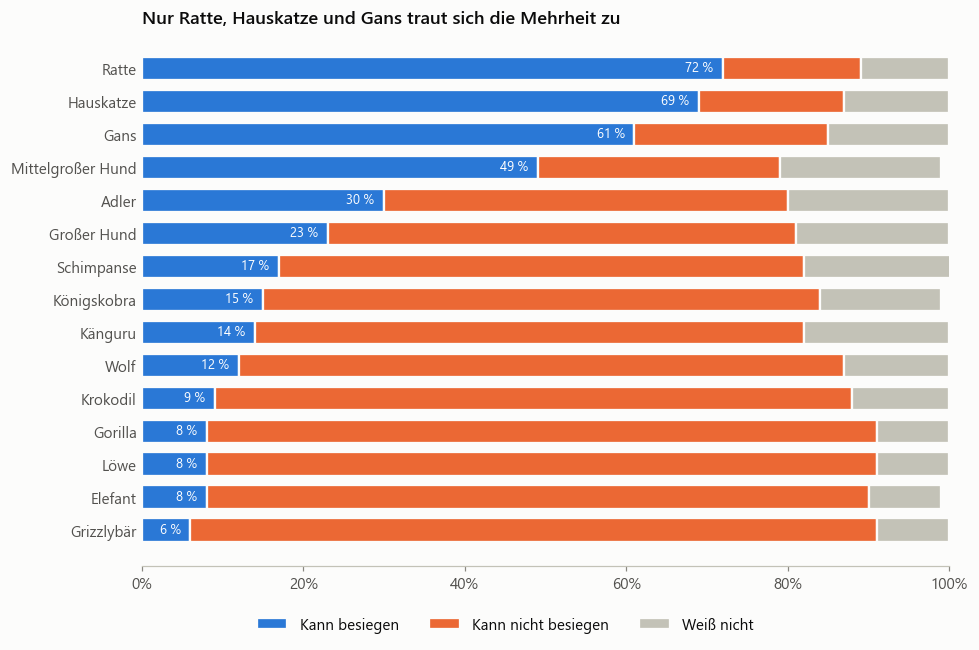

In [2]:
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(ORDER)); left = np.zeros(len(ORDER))
for col in RESP:
    ax.barh(y, total[col], left=left, height=0.7, color=RESP_COL[col], label=RESP_LABEL[col],
            edgecolor=SURFACE, linewidth=1.5)
    left += total[col].values
for i, v in enumerate(total['could_beat_pct']):
    ax.text(v - 1.2, i, f'{v} %', ha='right', va='center', fontsize=8.5,
            color='white')
ax.set_yticks(y, [DE[a] for a in ORDER]); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlim(0, 100)
ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.set_title('Nur Ratte, Hauskatze und Gans traut sich die Mehrheit zu')
ax.legend(loc='upper center', bbox_to_anchor=(0.45, -0.07), ncol=3)
plt.tight_layout(); plt.show()

## 1. Tabellenbasiert: Heatmap (Folie 5)

Die Tabellenform (Tier × Teilgruppe) bleibt erhalten, die Zahlen werden durch Farbe
ersetzt. **Links** der absolute Anteil „kann besiegen“ (sequenziell, eine Farbe hell → dunkel),
**rechts** die Abweichung jeder Teilgruppe vom Gesamtwert des Tieres (divergierend:
blau = zuversichtlicher, rot = weniger zuversichtlich, grau = kein Unterschied).

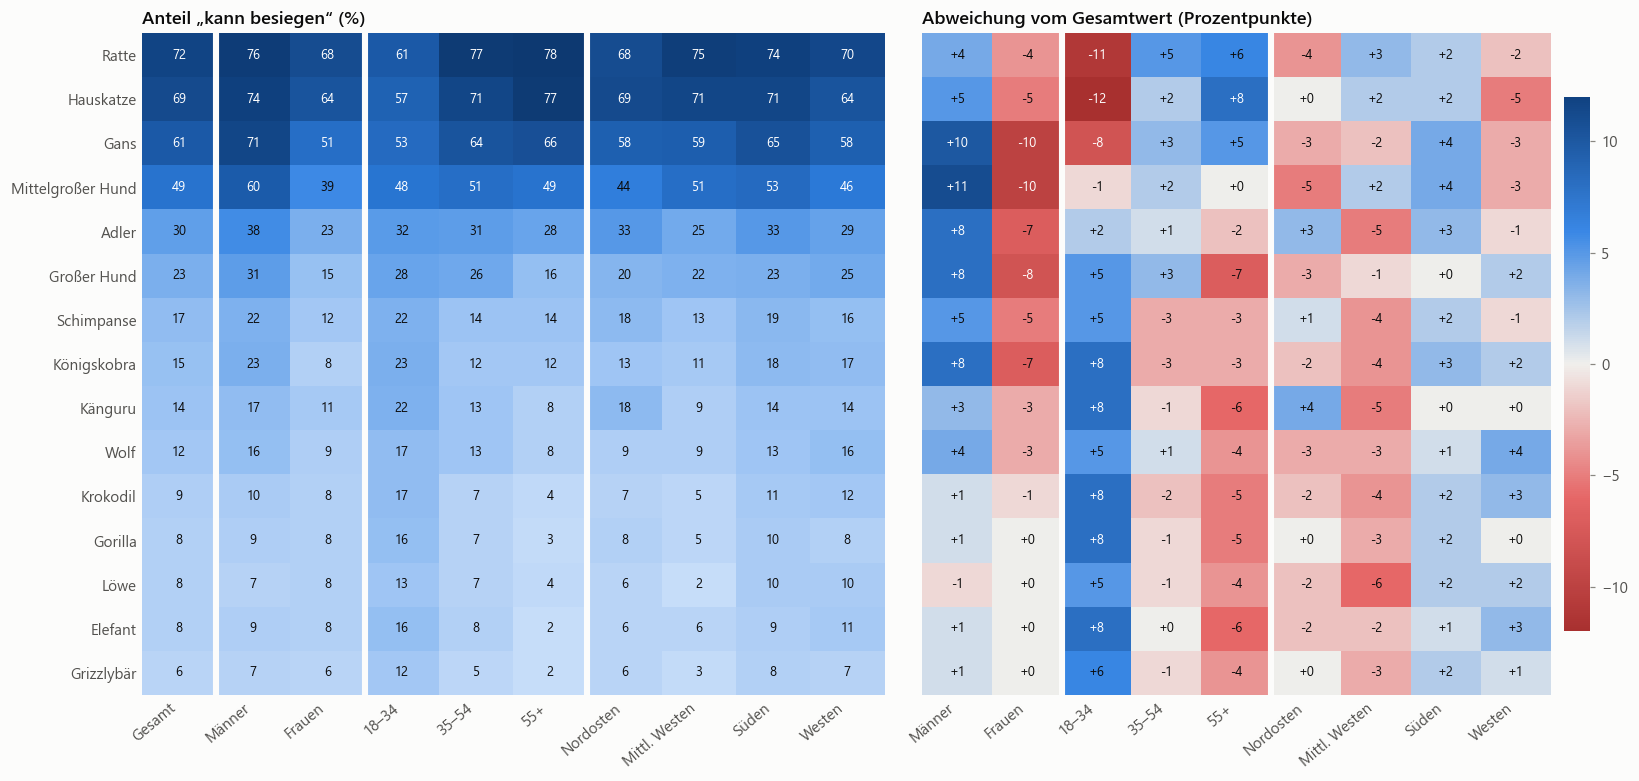

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7.2), gridspec_kw={'width_ratios': [10, 9]})
cols1 = ['Total'] + GROUPS
m1 = beat[cols1].values
ax1.imshow(m1, cmap=CMAP_SEQ, vmin=0, vmax=80, aspect='auto')
dev = beat[GROUPS].sub(beat['Total'], axis=0).values
lim = np.abs(dev).max()
im2 = ax2.imshow(dev, cmap=CMAP_DIV, norm=TwoSlopeNorm(0, -lim, lim), aspect='auto')

for ax, m, cols, fmt in [(ax1, m1, cols1, '{:.0f}'), (ax2, dev, GROUPS, '{:+.0f}')]:
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m[i, j]
            dark = (v > 45) if ax is ax1 else (abs(v) > 0.6 * lim)
            ax.text(j, i, fmt.format(v), ha='center', va='center', fontsize=8.5,
                    color='white' if dark else INK)
    ax.set_xticks(range(len(cols)), [GROUP_DE[c] for c in cols], rotation=40, ha='right')
    ax.set_yticks(range(len(ORDER)), [DE[a] for a in ORDER])
    ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    # Trennlinien zwischen Gruppenkategorien
    seps = [0.5, 2.5, 5.5] if ax is ax1 else [1.5, 4.5]
    for x in seps: ax.axvline(x, color=SURFACE, lw=4)
ax2.set_yticklabels([])
ax1.set_title('Anteil „kann besiegen“ (%)')
ax2.set_title('Abweichung vom Gesamtwert (Prozentpunkte)')
cb = fig.colorbar(im2, ax=ax2, fraction=0.04, pad=0.02); cb.outline.set_visible(False)
plt.tight_layout(); plt.show()

**Erkenntnis:** Links dominiert der Unterschied *zwischen den Tieren* (Zeilen) – die
Teilgruppen ändern das Gesamtbild kaum. Erst die Abweichungs-Heatmap rechts macht die
feineren Muster sichtbar: **Männer** sind fast durchgehend blau, **Frauen** rot; bei den
**18–34-Jährigen** kippt das Vorzeichen je nach Tier (weniger zuversichtlich bei
Ratte/Katze/Gans, eher zuversichtlicher bei gefährlichen Tieren). Die Regionen-Spalten
sind überwiegend grau – Region ist die schwächste Dimension.

## 2. Achsenbasiert: Streudiagramm Männer vs. Frauen (Folie 6)

Zwei Attribute auf orthogonalen Achsen, ein drittes über die Punktgröße
(„weiß nicht“-Anteil) und der Archetyp über die Farbe. Die Diagonale markiert
„kein Unterschied“ – je weiter ein Punkt darunter liegt, desto größer der Gender-Gap.

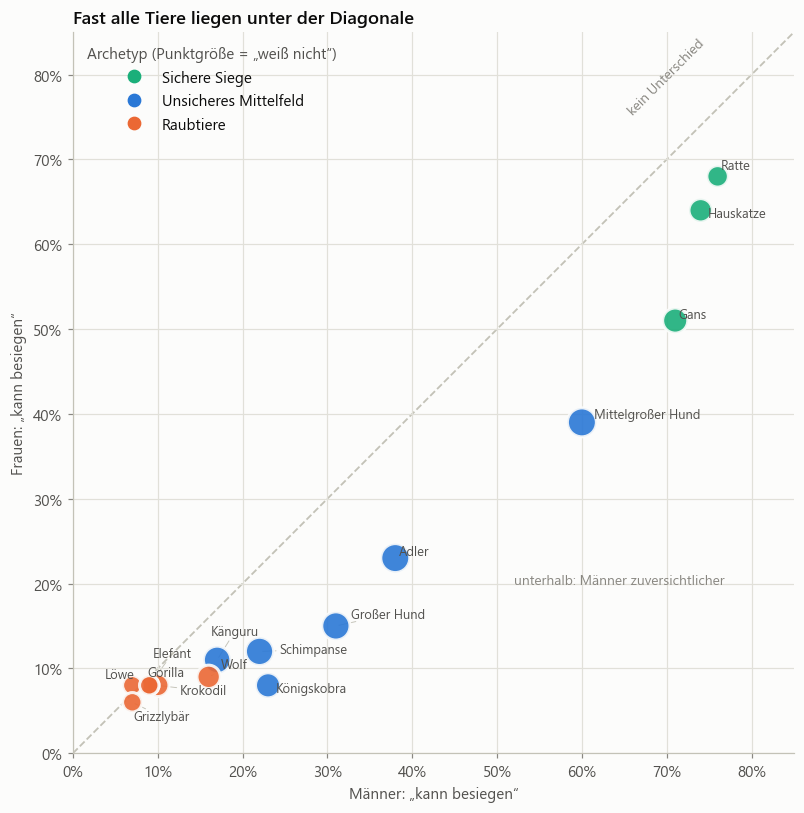

In [4]:
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.plot([0, 85], [0, 85], color=AXIS, lw=1.2, ls='--', zorder=1)
ax.text(70, 75, 'kein Unterschied', rotation=45, color=MUTED, fontsize=9, ha='center', va='bottom')
ax.text(52, 20, 'unterhalb: Männer zuversichtlicher', color=MUTED, fontsize=9)
ax.scatter(beat['Male'], beat['Female'], s=total['dont_know_pct'] * 18, c=acol,
           edgecolor=SURFACE, linewidth=2, zorder=3, alpha=0.9)
texts = [ax.text(beat.loc[a, 'Male'], beat.loc[a, 'Female'], DE[a], fontsize=8.5, color=INK2)
         for a in ORDER]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color=AXIS, lw=0.6))
ax.set_xlim(0, 85); ax.set_ylim(0, 85)
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Männer: „kann besiegen“'); ax.set_ylabel('Frauen: „kann besiegen“')
ax.grid(True, zorder=0); ax.set_aspect('equal')
ax.set_title('Fast alle Tiere liegen unter der Diagonale')
leg = arch_legend(ax, loc='upper left', title='Archetyp (Punktgröße = „weiß nicht“)')
leg.get_title().set_color(INK2)
plt.tight_layout(); plt.show()

**Erkenntnis:** 14 von 15 Tieren liegen unter der Diagonale – Männer trauen sich fast
durchgehend mehr zu (einzige Ausnahme: Löwe, 7 % vs. 8 %, also praktisch gleich). Der Abstand ist im mittleren Bereich (Mittelgroßer Hund, Adler,
Großer Hund) am größten; bei den Raubtieren nahe dem Ursprung ist er klein, weil sich
dort ohnehin kaum jemand einen Sieg zutraut.

## 3. Kombiniert bivariat: Scatterplot-Matrix / SPLOM (Folie 9)

Fünf abgeleitete Kennzahlen pro Tier, jedes Paar als eigenes Streudiagramm.
Die Diagonale zeigt die Verteilung der jeweiligen Kennzahl, das obere Dreieck die
Rangkorrelation ρ (fett = |ρ| ≥ 0,6). Der SPLOM eignet sich, um
Korrelationen, Cluster und Ausreißer gleichzeitig zu erkennen.

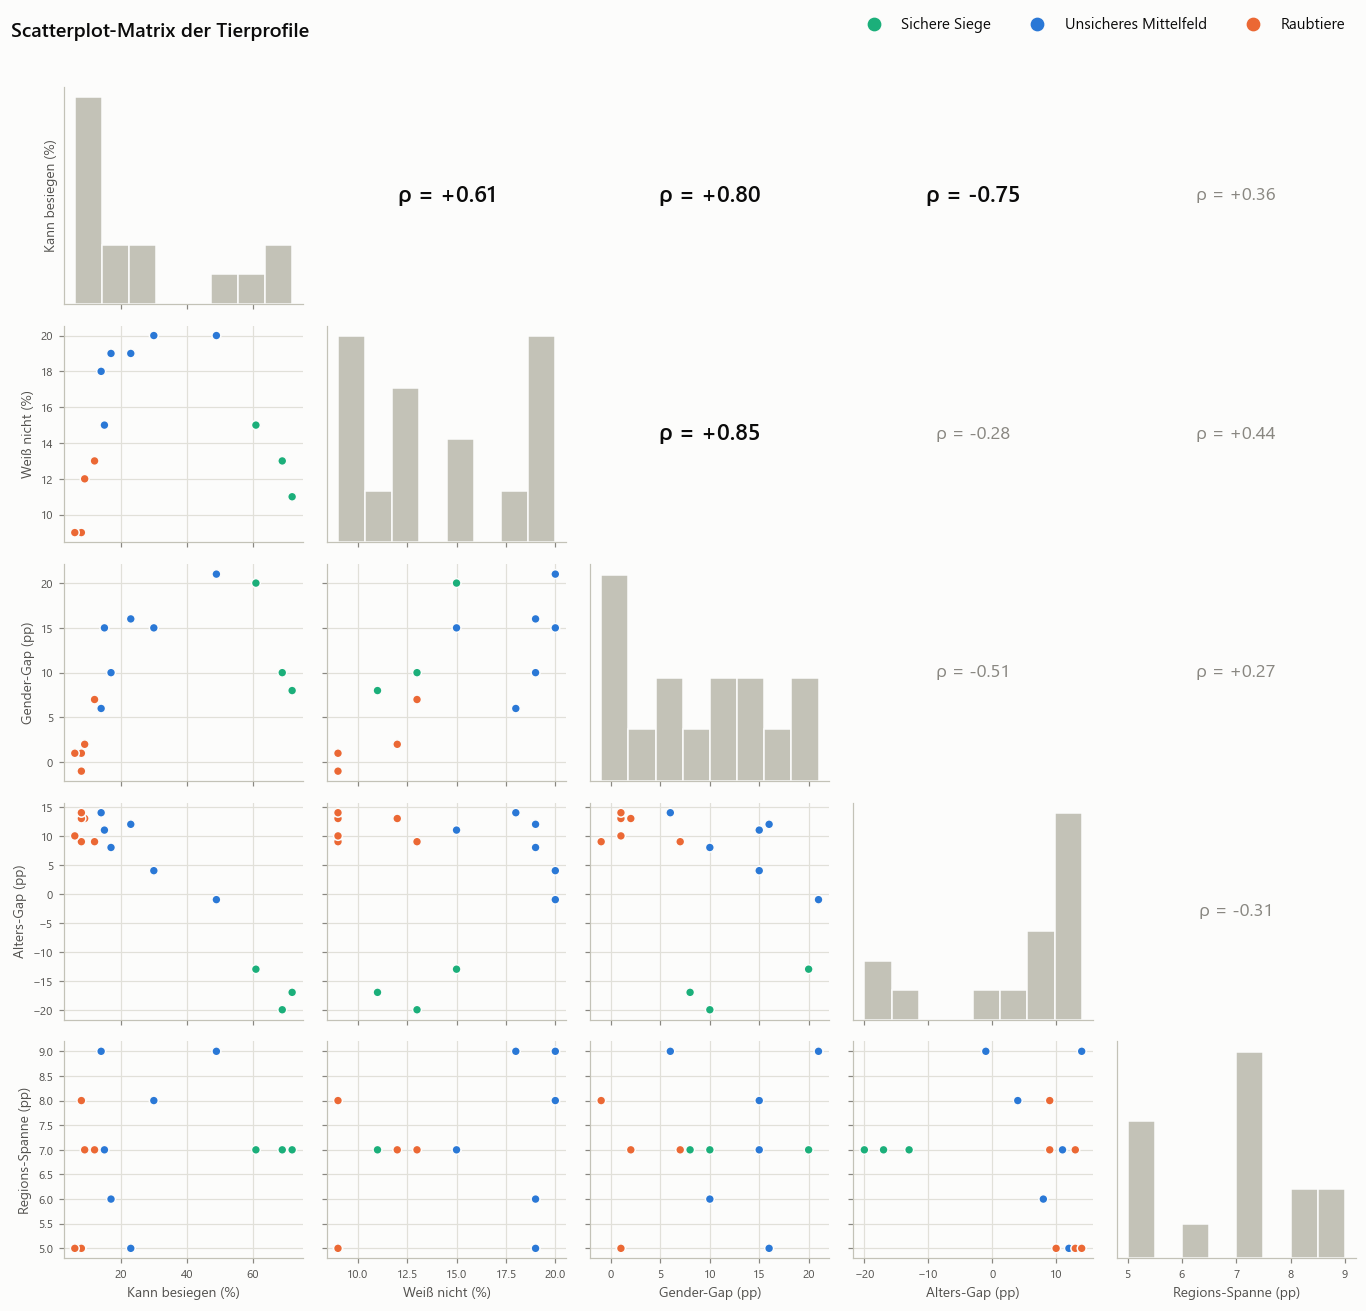

In [5]:
cols = feat.columns; k = len(cols)
fig, axes = plt.subplots(k, k, figsize=(12.5, 12))
for i, ci in enumerate(cols):
    for j, cj in enumerate(cols):
        ax = axes[i, j]
        if i == j:      # Diagonale: Verteilung
            ax.hist(feat[ci], bins=8, color=AXIS, edgecolor=SURFACE); ax.set_yticks([])
        elif i > j:     # unteres Dreieck: Streudiagramme
            ax.scatter(feat[cj], feat[ci], c=acol, s=34, edgecolor=SURFACE, linewidth=1, zorder=3)
            ax.grid(True, zorder=0)
        else:           # oberes Dreieck: Rangkorrelation (Spearman)
            r = feat[[ci, cj]].corr(method='spearman').iloc[0, 1]
            strong = abs(r) >= 0.6
            ax.text(0.5, 0.5, f'ρ = {r:+.2f}', transform=ax.transAxes, ha='center', va='center',
                    fontsize=15 if strong else 12, color=INK if strong else MUTED,
                    weight='semibold' if strong else 'normal')
            ax.axis('off'); continue
        ax.tick_params(labelsize=7.5)
        if i == k - 1: ax.set_xlabel(cj, fontsize=9)
        else: ax.set_xticklabels([])
        if j == 0: ax.set_ylabel(ci, fontsize=9)
        elif i != j: ax.set_yticklabels([])
fig.suptitle('Scatterplot-Matrix der Tierprofile', x=0.01, ha='left', fontsize=13, weight='semibold')
arch_legend(fig, loc='upper right', ncol=3, bbox_to_anchor=(0.99, 0.995))
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

**Erkenntnis:** Die Archetypen trennen sich in fast jedem Panel klar. „Kann besiegen“ und
„Alters-Gap“ hängen stark negativ zusammen (ρ ≈ −0,75) – bei ungefährlichen Tieren sind die
Älteren zuversichtlicher, bei gefährlichen die Jüngeren. Auffällig ist auch
Gender-Gap ↔ „Weiß nicht“ (ρ ≈ +0,85): Wo viele unsicher sind, gehen Männer und Frauen am
weitesten auseinander. „Weiß nicht“ ist im
Mittelfeld am höchsten (umgekehrtes U-Muster), was eine lineare Korrelation unterschätzt.

## 4. Polyline-basiert: Parallele Koordinaten (Folien 10–12)

Jede der 9 Teilgruppen ist eine vertikale Achse, jedes Tier eine Linie. Da alle Achsen
dieselbe Einheit (%) haben, verwenden wir eine **gemeinsame Skala** – so sind Niveaus
und Steigungen direkt vergleichbar. Parallele Linien = gleiches Muster, Kreuzungen =
Rangwechsel zwischen Teilgruppen.

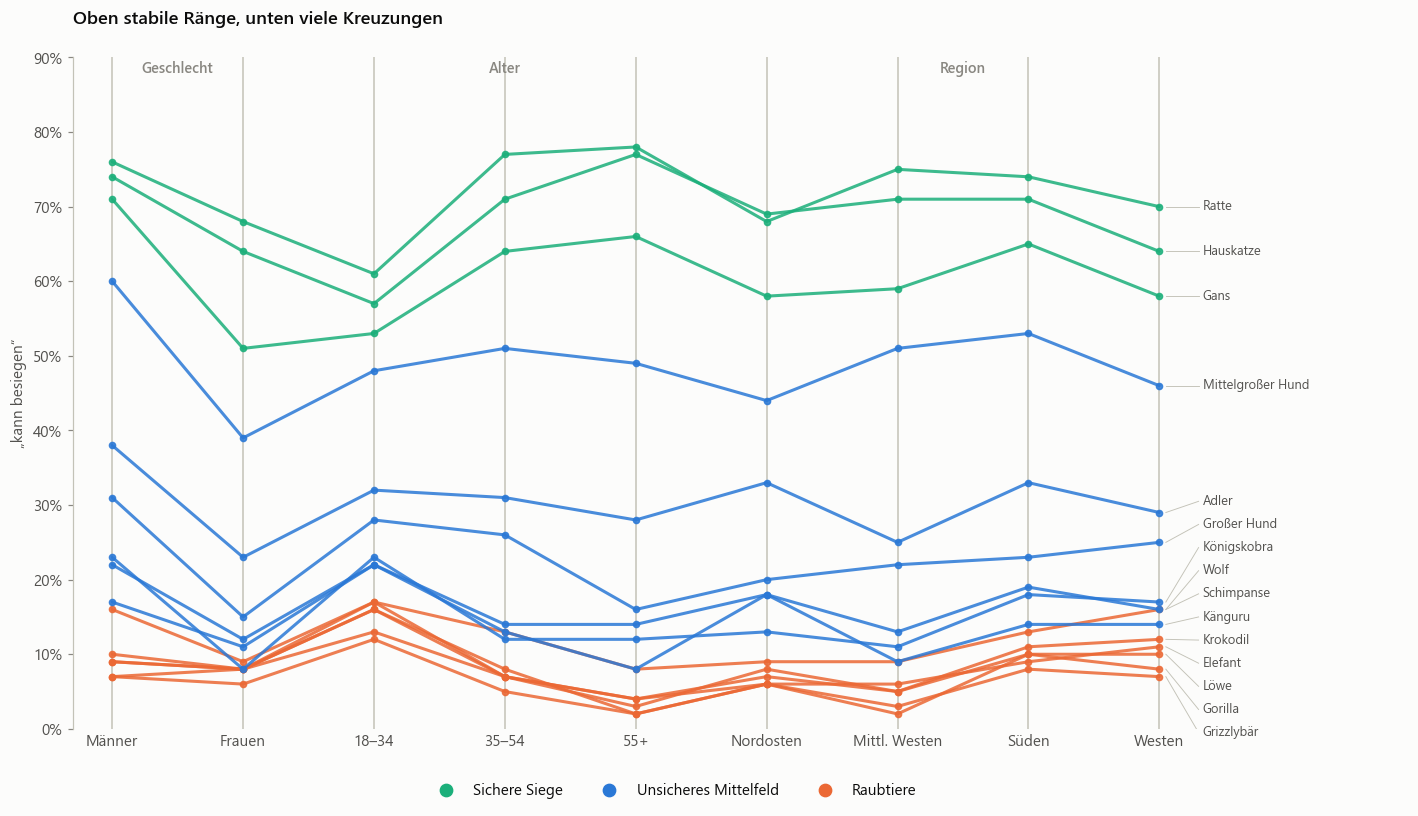

In [6]:
fig, ax = plt.subplots(figsize=(13, 7.5))
x = np.arange(len(GROUPS))
for a in ORDER[::-1]:
    ax.plot(x, beat.loc[a, GROUPS], color=ARCH_COL[arch[a]], lw=2, alpha=0.85,
            marker='o', ms=4, solid_capstyle='round')
for xi in x: ax.axvline(xi, color=AXIS, lw=1, zorder=0)
for xi in [1.5, 4.5]: ax.axvspan(xi - 0.02, xi + 0.02, color=SURFACE)
# Beschriftung am rechten Rand, kollisionsfrei verteilt
yl = spread(beat[GROUPS[-1]].values, 3.1)
for a, yv, ylab in zip(ORDER, beat[GROUPS[-1]], yl):
    ax.plot([x[-1] + 0.05, x[-1] + 0.3], [yv, ylab], color=AXIS, lw=0.6)
    ax.text(x[-1] + 0.33, ylab, DE[a], va='center', fontsize=8.5, color=INK2)
for xi, lab in zip([0.5, 3, 6.5], ['Geschlecht', 'Alter', 'Region']):
    ax.text(xi, 88, lab, ha='center', color=MUTED, fontsize=9.5, weight='semibold')
ax.set_xticks(x, [GROUP_DE[g] for g in GROUPS])
ax.set_xlim(-0.3, len(GROUPS) + 0.9); ax.set_ylim(0, 90)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.spines['bottom'].set_visible(False); ax.tick_params(axis='x', length=0)
ax.set_ylabel('„kann besiegen“')
ax.set_title('Oben stabile Ränge, unten viele Kreuzungen', pad=22)
arch_legend(ax, loc='upper center', bbox_to_anchor=(0.45, -0.06), ncol=3)
plt.tight_layout(); plt.show()

**Erkenntnis:** Die oberen vier Linien (Ratte, Katze, Gans, Mittelgroßer Hund) kreuzen
sich kaum – ihre Rangfolge ist in jeder Teilgruppe gleich. Unter ~30 % liegen Mittelfeld
und Raubtiere dagegen eng beieinander und kreuzen sich häufig, d. h. die Reihenfolge der
gefährlichen Tiere ist nicht stabil. Die Segmente Männer → Frauen fallen fast überall; im
Altersblock steigen die grünen Linien, während die unteren fallen – der gegenläufige
Alterseffekt. Im Regionsblock gibt es nur kleine Zickzacks ohne gemeinsame Richtung.

## 5. Radar-Chart (Folie 13)

Polarkoordinaten: jedes Tier ist ein Winkel, der Anteil „kann besiegen“ der Radius.
Zwei Radar-Charts vergleichen die Profile der Geschlechter bzw. der Altersgruppen
als überlagerte Formen. (Laut Folie: Winkel werden ungenauer wahrgenommen als Positionen –
das Radar zeigt die **Gesamtform**, für exakte Werte siehe Heatmap.)

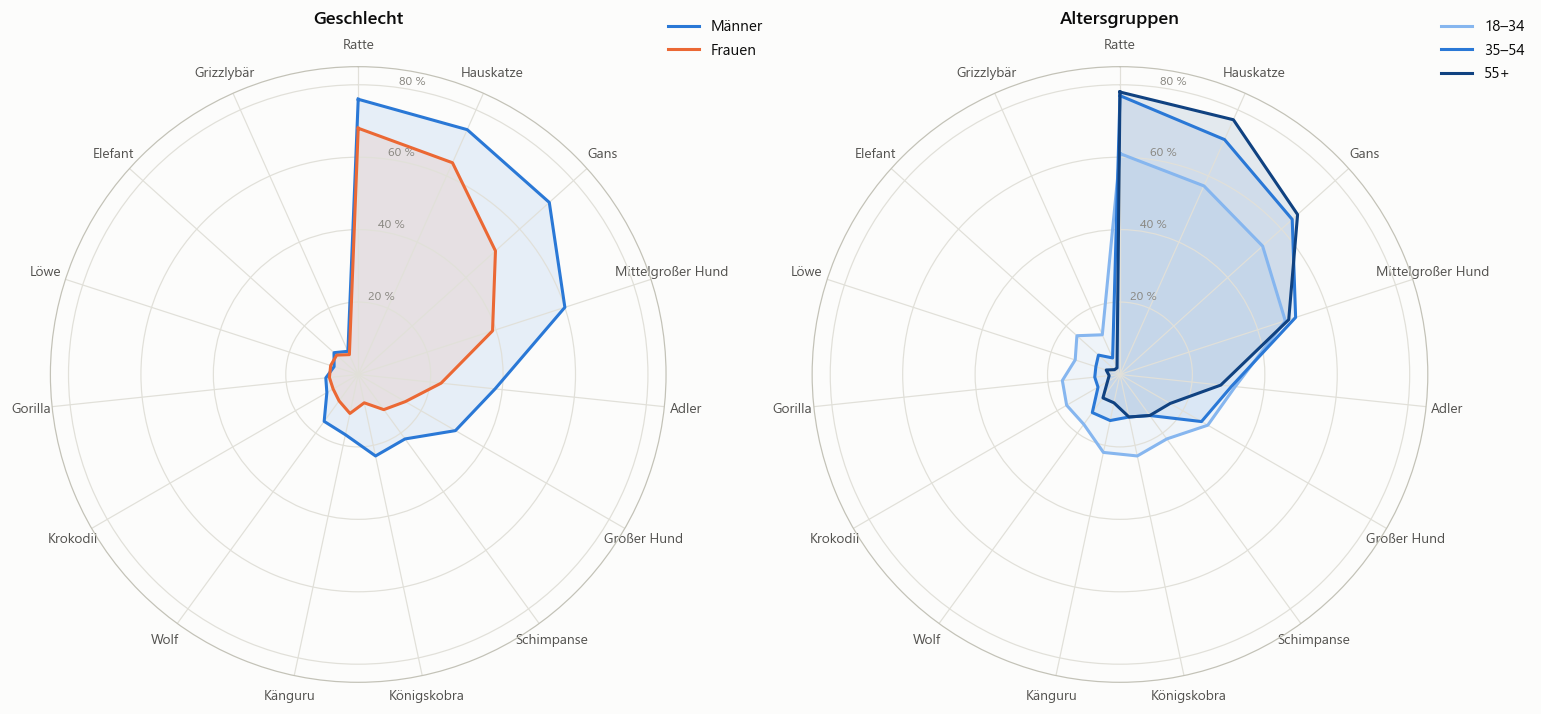

In [7]:
theta = np.linspace(0, 2 * np.pi, len(ORDER), endpoint=False)
close = lambda v: np.r_[v, v[:1]]
fig, axes = plt.subplots(1, 2, figsize=(14, 7), subplot_kw={'projection': 'polar'})
series = [
    ('Geschlecht', [('Male', BLUE, 'Männer'), ('Female', ORANGE, 'Frauen')]),
    ('Altersgruppen', [(g, AGE_COL[g], GROUP_DE[g]) for g in AGE]),
]
for ax, (title, groups) in zip(axes, series):
    for g, c, lab in groups:
        v = beat.loc[ORDER, g].values
        ax.plot(close(theta), close(v), color=c, lw=2, label=lab)
        ax.fill(close(theta), close(v), color=c, alpha=0.10)
    ax.set_theta_offset(np.pi / 2); ax.set_theta_direction(-1)
    ax.set_xticks(theta, [DE[a] for a in ORDER], fontsize=9, color=INK2)
    ax.set_ylim(0, 85); ax.set_yticks([20, 40, 60, 80], ['20 %', '40 %', '60 %', '80 %'], color=MUTED, fontsize=8)
    ax.set_rlabel_position(8)
    ax.grid(color=GRID); ax.spines['polar'].set_color(AXIS)
    ax.set_title(title, pad=28, loc='center')
    ax.legend(loc='upper right', bbox_to_anchor=(1.18, 1.1))
plt.tight_layout(); plt.show()

**Erkenntnis:** Das Männer-Polygon umschließt das Frauen-Polygon fast vollständig
(einzige Ausnahme: Löwe, 7 % vs. 8 %). Bei den
Altersgruppen ist das Bild gemischt: 55+ (dunkel) ragt bei Ratte/Katze/Gans am weitesten
hinaus, 18–34 (hell) liegt dort innen, aber bei den gefährlichen Tieren knapp außen –
die Formen *schneiden* sich, die Polygone sind nicht ineinander geschachtelt.

## 6. Glyphen: Star Plots im Raster (Folien 16, 19, 21)

Jedes Tier ist ein **Star Plot**: die 5 abgeleiteten Kennzahlen werden auf die Länge der
Strahlen abgebildet (*Many-to-One-Mapping*), der Umriss betont die Form.
Jede Kennzahl ist über alle Tiere auf 0–1 normiert (Min–Max). Die Farbe kodiert den
Archetyp (kategoriales Attribut). Das Raster erleichtert den direkten Formvergleich.

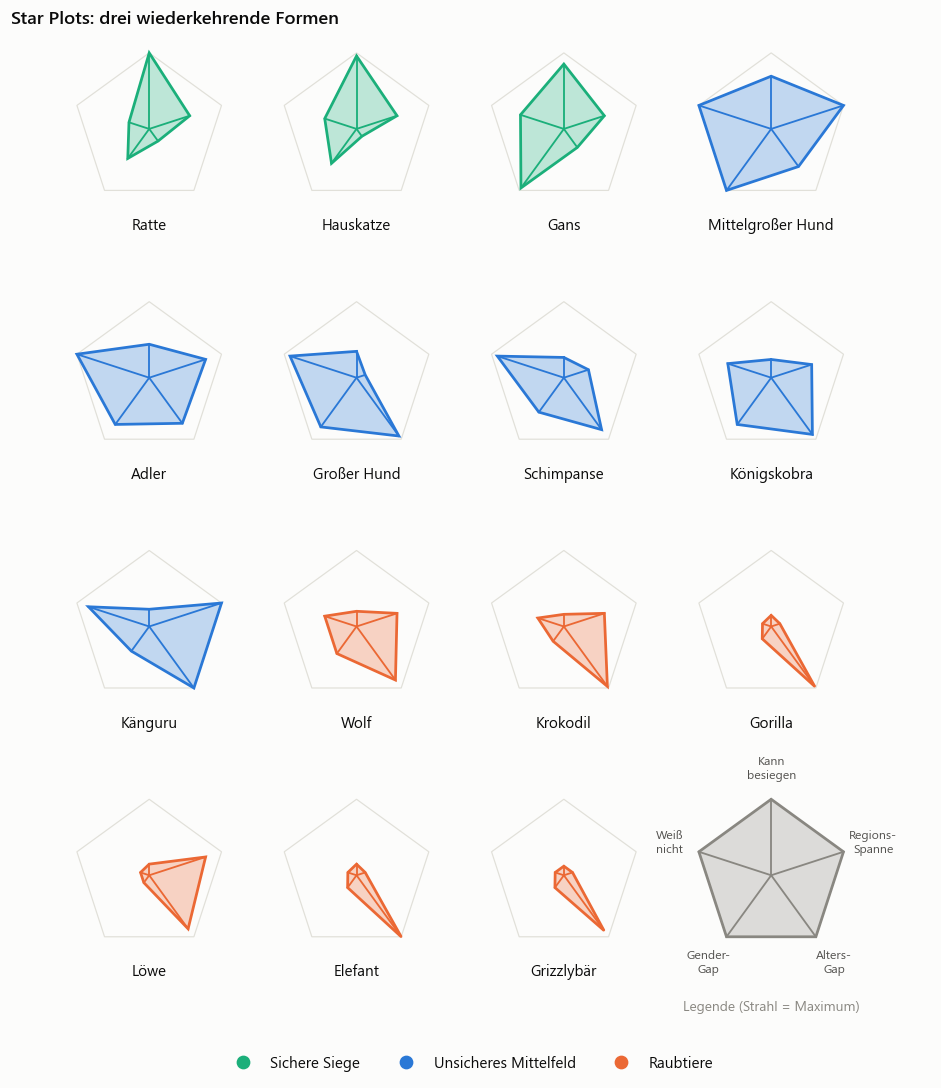

In [8]:
norm = (feat - feat.min()) / (feat.max() - feat.min())
ang = np.linspace(0, 2 * np.pi, feat.shape[1], endpoint=False) + np.pi / 2
SHORT = ['Kann\nbesiegen', 'Weiß\nnicht', 'Gender-\nGap', 'Alters-\nGap', 'Regions-\nSpanne']

def star(ax, cx, cy, vals, r, color, ref=True):
    xs = cx + r * (0.12 + 0.88 * vals) * np.cos(ang)
    ys = cy + r * (0.12 + 0.88 * vals) * np.sin(ang)
    if ref:
        ax.add_patch(Polygon(np.c_[cx + r * np.cos(ang), cy + r * np.sin(ang)], fill=False,
                             ec=GRID, lw=0.8))
    for xe, ye in zip(xs, ys):
        ax.plot([cx, xe], [cy, ye], color=color, lw=1.2)
    ax.add_patch(Polygon(np.c_[xs, ys], fc=color, ec=color, alpha=0.28, lw=0))
    ax.add_patch(Polygon(np.c_[xs, ys], fill=False, ec=color, lw=1.8))

fig, ax = plt.subplots(figsize=(12, 10))
ncol = 4
for idx, a in enumerate(ORDER):
    cx, cy = (idx % ncol) * 3, -(idx // ncol) * 3.6
    star(ax, cx, cy, norm.loc[a].values, 1.1, ARCH_COL[arch[a]])
    ax.text(cx, cy - 1.45, DE[a], ha='center', fontsize=10, color=INK)
# Legenden-Glyphe im letzten Feld
cx, cy = 3 * 3, -3 * 3.6
star(ax, cx, cy, np.ones(5), 1.1, MUTED)
for an, lab in zip(ang, SHORT):
    ax.text(cx + 1.55 * np.cos(an), cy + 1.55 * np.sin(an), lab, ha='center', va='center',
            fontsize=8, color=INK2)
ax.text(cx, cy - 1.95, 'Legende (Strahl = Maximum)', ha='center', fontsize=9, color=MUTED)
ax.set_xlim(-2, 11.3); ax.set_ylim(-13.2, 1.4); ax.set_aspect('equal'); ax.axis('off')
ax.set_title('Star Plots: drei wiederkehrende Formen')
arch_legend(ax, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=3)
plt.tight_layout(); plt.show()

**Erkenntnis:** Die Formen wiederholen sich innerhalb der Archetypen:
*Sichere Siege* haben einen langen „Kann besiegen“-Strahl (oben) und einen minimalen
„Alters-Gap“-Strahl (unten rechts – hier sind die Älteren zuversichtlicher);
*Raubtiere* sind schmale Glyphen, die fast nur nach unten rechts zeigen (großer
Alters-Gap = Jüngere zuversichtlicher), sonst aber kaum Ausdehnung haben; das *Mittelfeld* hat die breitesten
Formen mit langen Strahlen bei „Weiß nicht“, „Gender-Gap“ und „Regions-Spanne“.

## 7. Dimensionsreduktion + Glyph-Platzierung (Folien 7, 21)

Die 5 Kennzahlen werden standardisiert und per **PCA** auf 2 Dimensionen projiziert:
Ähnlichkeit im 5-D-Raum wird zu räumlicher Nähe. An jeder Position steht statt eines
Punkts die Star-Glyphe des Tieres – so bleibt sichtbar, *warum* zwei Tiere nah beieinander liegen.

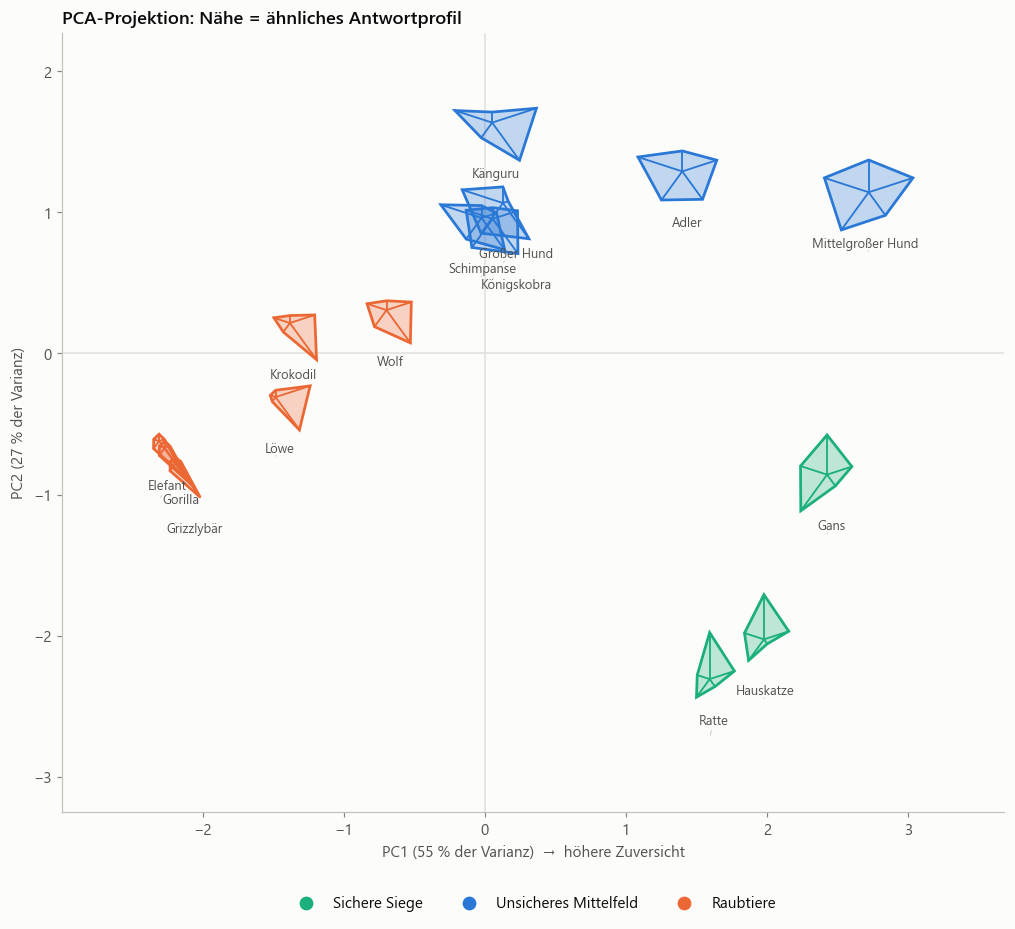

,PC1,PC2
Kann besiegen (%),0.52,-0.42
Weiß nicht (%),0.38,0.61
Gender-Gap (pp),0.51,0.27
Alters-Gap (pp),-0.46,0.55
Regions-Spanne (pp),0.34,0.28


In [9]:
X = StandardScaler().fit_transform(feat)
pca = PCA(n_components=2, random_state=0).fit(X)
P = pca.transform(X)
if np.corrcoef(P[:, 0], feat['Kann besiegen (%)'])[0, 1] < 0: P[:, 0] *= -1   # PC1: rechts = zuversichtlicher

fig, ax = plt.subplots(figsize=(12, 8.5))
ax.axhline(0, color=GRID, lw=1, zorder=0); ax.axvline(0, color=GRID, lw=1, zorder=0)
for (px, py), a in zip(P, ORDER):
    star(ax, px, py, norm.loc[a].values, 0.33, ARCH_COL[arch[a]], ref=False)
texts = [ax.text(px, py - 0.42, DE[a], ha='center', fontsize=8.5, color=INK2) for (px, py), a in zip(P, ORDER)]
adjust_text(texts, ax=ax, only_move={'text': 'y'}, arrowprops=dict(arrowstyle='-', color=AXIS, lw=0.5))
ev = pca.explained_variance_ratio_ * 100
ax.set_xlabel(f'PC1 ({ev[0]:.0f} % der Varianz)  →  höhere Zuversicht')
ax.set_ylabel(f'PC2 ({ev[1]:.0f} % der Varianz)')
ax.set_aspect('equal'); ax.margins(0.12)
ax.set_title('PCA-Projektion: Nähe = ähnliches Antwortprofil')
arch_legend(ax, loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=3)
plt.tight_layout(); plt.show()

pd.DataFrame(pca.components_.T * [np.sign(np.corrcoef(pca.transform(X)[:, 0], P[:, 0])[0, 1]), 1],
             index=feat.columns, columns=['PC1', 'PC2']).round(2)

**Erkenntnis:** Die Projektion bestätigt die drei Gruppen ohne dass die Archetypen als
Eingabe verwendet wurden: die Raubtiere bilden ein enges Cluster (sehr ähnliche Glyphen),
die sicheren Siege liegen rechts unten, das Mittelfeld oben. PC1 (55 %) ist im Wesentlichen
„Zuversicht + Gender-Gap“, PC2 (27 %) trennt laut Ladungstabelle Tiere mit hohem
„weiß nicht“-Anteil und positivem Alters-Gap (Mittelfeld, oben) von den sicheren Siegen (unten).

## 8. Verschachtelt: Mosaik-Plot (Folie 25)

Rekursive Aufteilung der Fläche: zuerst horizontal nach Altersgruppe (Breite ∝ gewichtete
Gruppengröße), dann vertikal nach Antwort. Die **Fläche** jeder Zelle entspricht dem Anteil
der Befragten mit dieser Kombination. Vier Tiere aus den drei Archetypen im Vergleich.

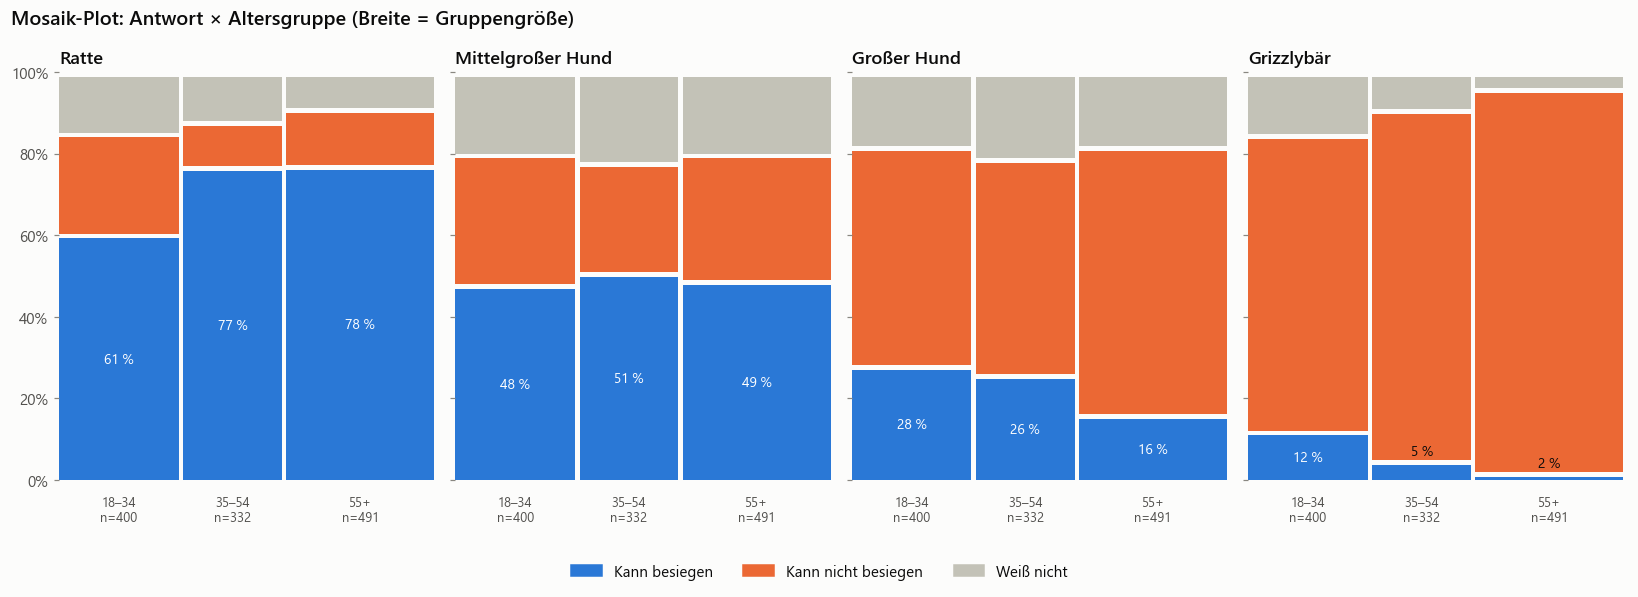

In [10]:
MOSAIC = ['Rat', 'Medium sized dog', 'Large dog', 'Grizzly bear']
fig, axes = plt.subplots(1, 4, figsize=(15, 5.2), sharey=True)
gap = 0.012
for ax, a in zip(axes, MOSAIC):
    sub = df[(df['animal'] == a) & (df['group_category'] == 'Age')].set_index('group').loc[AGE]
    w = sub['base_weighted'] / sub['base_weighted'].sum()
    x0 = 0
    for g in AGE:
        wi = w[g] - gap; y0 = 0
        for col in RESP:
            h = sub.loc[g, col] / sub.loc[g, RESP].sum()
            ax.add_patch(Rectangle((x0, y0), wi, h - gap, color=RESP_COL[col], lw=0))
            if col == 'could_beat_pct':
                ax.text(x0 + wi / 2, y0 + (h - gap) / 2 if h > 0.08 else y0 + h + 0.02,
                        f'{sub.loc[g, col]} %', ha='center', va='center', fontsize=9,
                        color='white' if h > 0.08 else INK)
            y0 += h
        ax.text(x0 + wi / 2, -0.04, f'{GROUP_DE[g]}\nn={sub.loc[g, "base_weighted"]}', ha='center',
                va='top', fontsize=8.5, color=INK2)
        x0 += w[g]
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xticks([])
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(DE[a], color=ARCH_COL[arch[a]] if False else INK)
handles = [Rectangle((0, 0), 1, 1, color=RESP_COL[c], label=RESP_LABEL[c]) for c in RESP]
fig.legend(handles=handles, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('Mosaik-Plot: Antwort × Altersgruppe (Breite = Gruppengröße)', x=0.01, ha='left',
             fontsize=13, weight='semibold')
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

**Erkenntnis:** Bei der Ratte wächst die blaue Fläche mit dem Alter, beim Grizzlybär
schrumpft sie – die Gegenläufigkeit des Alterseffekts wird als Flächenverschiebung sichtbar.
Die Breiten zeigen außerdem, dass 55+ die größte (gewichtete) Gruppe ist und damit den
Gesamtwert am stärksten prägt.

## 9. Parallel Sets / Alluvial-Diagramm (Folie 14)

Kategoriale Achsen, deren Kategorien nach Häufigkeit skaliert sind; Bänder zeigen, wie
viele (gewichtete) Befragte jeder Altersgruppe welche Antwort gaben.
*Hinweis:* Der Datensatz enthält nur Randverteilungen (keine Kreuztabelle Alter × Geschlecht),
daher sind nur **zwei** Achsen (Gruppe → Antwort) zulässig.

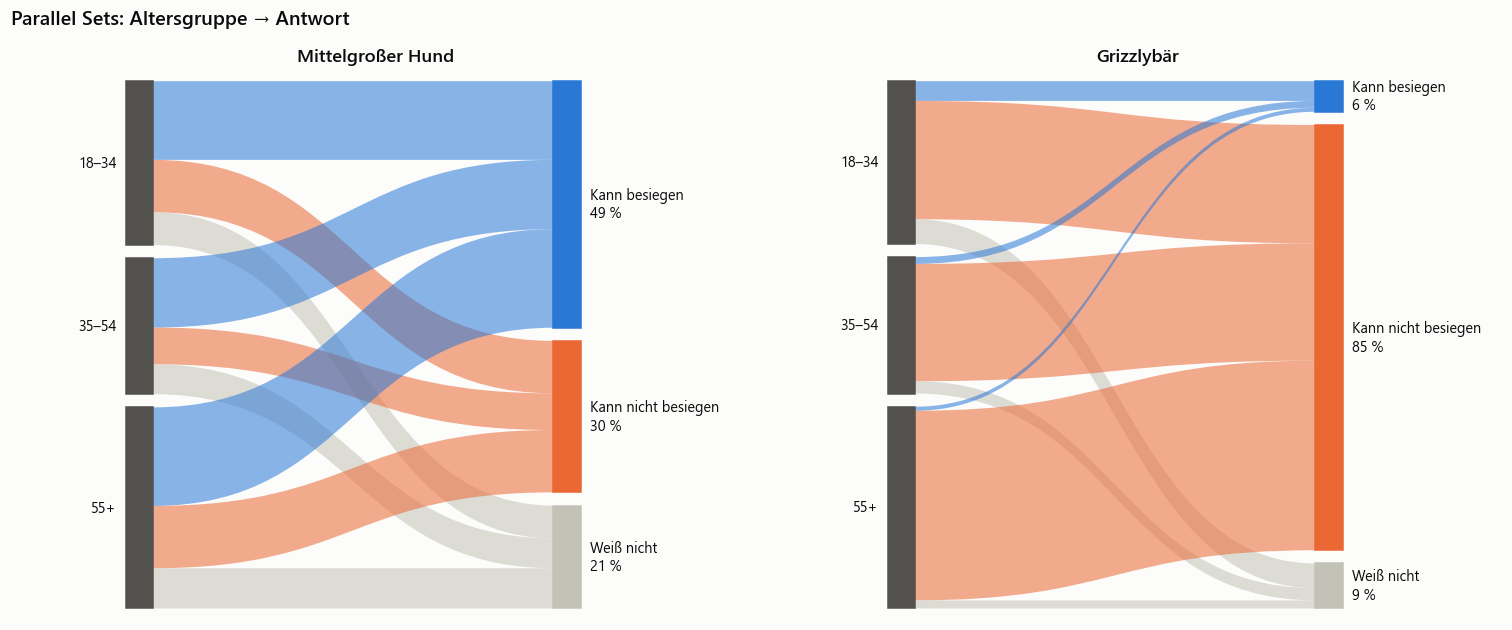

In [11]:
def ribbon(ax, x0, a0, b0, x1, a1, b1, color):
    xm = (x0 + x1) / 2
    verts = [(x0, a0), (xm, a0), (xm, a1), (x1, a1), (x1, b1), (xm, b1), (xm, b0), (x0, b0), (x0, a0)]
    codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.LINETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]
    ax.add_patch(PathPatch(Path(verts, codes), fc=color, ec='none', alpha=0.55))

def parallel_sets(ax, animal, cat='Age', groups=AGE):
    sub = df[(df['animal'] == animal) & (df['group_category'] == cat)].set_index('group').loc[groups]
    cnt = sub[RESP].mul(sub['base_weighted'], axis=0) / 100      # gewichtete Personen
    N, pad, bw = cnt.values.sum(), 0.025, 0.06
    scale = (1 - pad * (len(groups) - 1)) / N
    # linke Achse: Gruppen, rechte Achse: Antworten (jeweils von oben nach unten)
    ltop, y = {}, 1.0
    for g in groups:
        ltop[g] = y; y -= cnt.loc[g].sum() * scale + pad
    scale_r = (1 - pad * (len(RESP) - 1)) / N
    rtop, y = {}, 1.0
    for c in RESP:
        rtop[c] = y; y -= cnt[c].sum() * scale_r + pad
    lcur, rcur = dict(ltop), dict(rtop)
    for g in groups:
        for c in RESP:
            h = cnt.loc[g, c] * scale
            ribbon(ax, bw, lcur[g], lcur[g] - h, 1 - bw, rcur[c], rcur[c] - h, RESP_COL[c])
            lcur[g] -= h; rcur[c] -= h
    for g in groups:
        h = cnt.loc[g].sum() * scale
        ax.add_patch(Rectangle((0, ltop[g] - h), bw, h, color=INK2))
        ax.text(-0.02, ltop[g] - h / 2, f'{GROUP_DE[g]}', ha='right', va='center', fontsize=9.5)
    for c in RESP:
        h = cnt[c].sum() * scale_r
        ax.add_patch(Rectangle((1 - bw, rtop[c] - h), bw, h, color=RESP_COL[c]))
        ax.text(1.02, rtop[c] - h / 2, f'{RESP_LABEL[c]}\n{cnt[c].sum() / N * 100:.0f} %',
                ha='left', va='center', fontsize=9.5)
    ax.set_xlim(-0.25, 1.35); ax.set_ylim(-0.02, 1.02); ax.axis('off')
    ax.set_title(DE[animal], loc='center')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
parallel_sets(axes[0], 'Medium sized dog')
parallel_sets(axes[1], 'Grizzly bear')
fig.suptitle('Parallel Sets: Altersgruppe → Antwort', x=0.01, ha='left', fontsize=13, weight='semibold')
plt.tight_layout(); plt.show()

**Erkenntnis:** Beim Mittelgroßen Hund sind die Anteile in allen Altersgruppen fast gleich
(48 / 51 / 49 %) – Unterschiede in der Bandbreite kommen hier nur von der Gruppengröße.
Beim Grizzlybär ist der blaue Strom dünn und stammt überwiegend von den 18–34-Jährigen
(12 % vs. 2 % bei 55+). Außerdem sieht man, wie groß „weiß nicht“ beim Hund ist – ein
Fünftel aller Befragten, mehr als doppelt so viel wie beim Grizzlybär.

## 10. Räumlich: Grid-Kartogramm der US-Regionen (Folie 59)

Ein Grid-Kartogramm (gleich große Kacheln, ungefähre geografische Lage) vermeidet das
Choroplethen-Problem, dass große, dünn besiedelte Staaten optisch dominieren (Folie 54:
*„Land doesn't vote. People do.“*). Die Daten liegen nur auf Ebene der **4 Census-Regionen**
vor – alle Staaten einer Region haben deshalb dieselbe Farbe. Farbe = Abweichung vom
Gesamtwert des Tieres (divergierend). Gezeigt werden die 4 Tiere mit der größten regionalen Spanne.

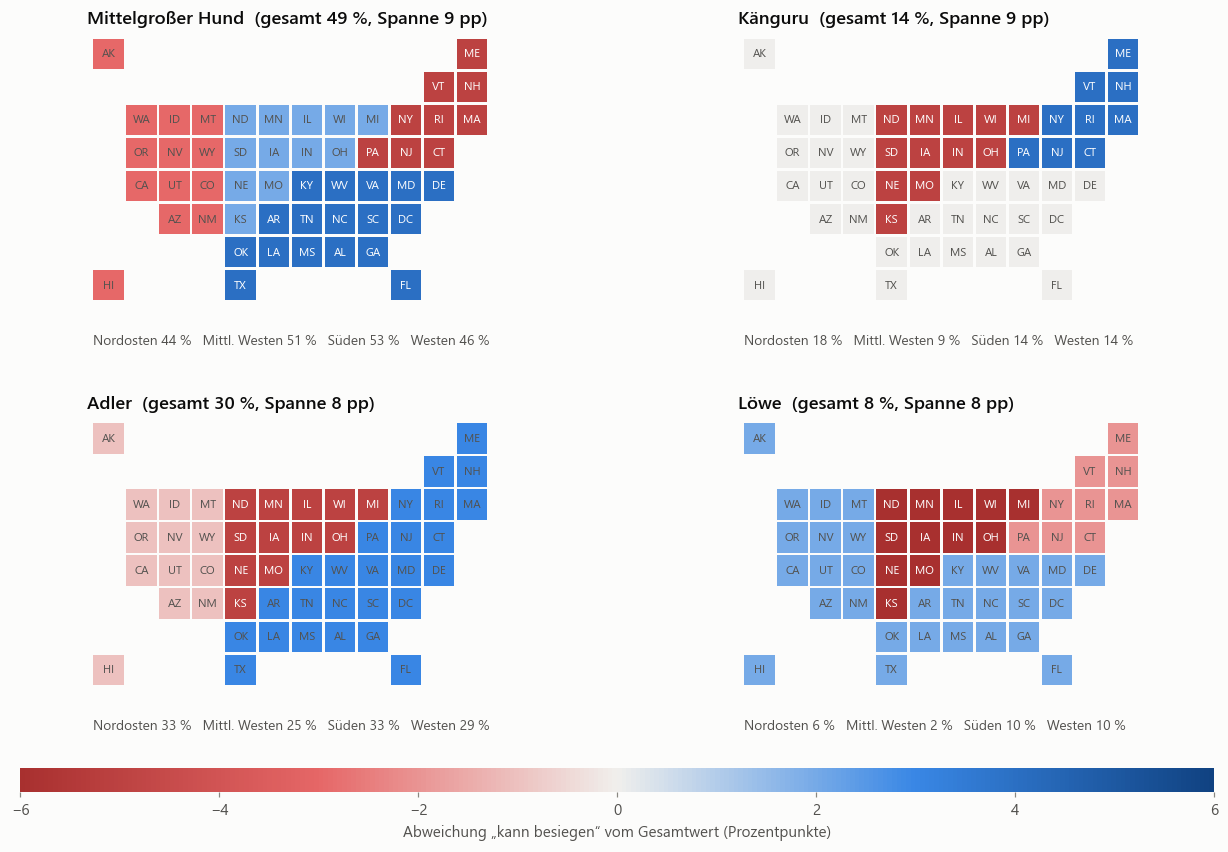

In [12]:
TILES = {  # Staat: (Spalte, Zeile)
    'AK': (0, 0), 'ME': (11, 0), 'VT': (10, 1), 'NH': (11, 1),
    'WA': (1, 2), 'ID': (2, 2), 'MT': (3, 2), 'ND': (4, 2), 'MN': (5, 2), 'IL': (6, 2), 'WI': (7, 2),
    'MI': (8, 2), 'NY': (9, 2), 'RI': (10, 2), 'MA': (11, 2),
    'OR': (1, 3), 'NV': (2, 3), 'WY': (3, 3), 'SD': (4, 3), 'IA': (5, 3), 'IN': (6, 3), 'OH': (7, 3),
    'PA': (8, 3), 'NJ': (9, 3), 'CT': (10, 3),
    'CA': (1, 4), 'UT': (2, 4), 'CO': (3, 4), 'NE': (4, 4), 'MO': (5, 4), 'KY': (6, 4), 'WV': (7, 4),
    'VA': (8, 4), 'MD': (9, 4), 'DE': (10, 4),
    'AZ': (2, 5), 'NM': (3, 5), 'KS': (4, 5), 'AR': (5, 5), 'TN': (6, 5), 'NC': (7, 5), 'SC': (8, 5),
    'DC': (9, 5), 'OK': (4, 6), 'LA': (5, 6), 'MS': (6, 6), 'AL': (7, 6), 'GA': (8, 6),
    'HI': (0, 7), 'TX': (4, 7), 'FL': (9, 7),
}
REGION_OF = {}
for r, states in {
    'Northeast': 'CT ME MA NH RI VT NJ NY PA',
    'Midwest': 'IL IN MI OH WI IA KS MN MO NE ND SD',
    'South': 'DE FL GA MD NC SC VA DC WV AL KY MS TN AR LA OK TX',
    'West': 'AZ CO ID MT NV NM UT WY AK CA HI OR WA',
}.items():
    for s in states.split(): REGION_OF[s] = r

top4 = feat['Regions-Spanne (pp)'].sort_values(ascending=False).index[:4]
regdev = beat.loc[top4, REGION].sub(beat.loc[top4, 'Total'], axis=0)
lim = np.abs(regdev.values).max()
dnorm = TwoSlopeNorm(0, -lim, lim)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, a in zip(axes.flat, top4):
    for s, (c, r) in TILES.items():
        v = regdev.loc[a, REGION_OF[s]]
        ax.add_patch(Rectangle((c, -r), 0.92, 0.92, color=CMAP_DIV(dnorm(v)), lw=0))
        ax.text(c + 0.46, -r + 0.46, s, ha='center', va='center', fontsize=7.5,
                color='white' if abs(v) > 0.6 * lim else INK2)
    lines = '   '.join(f'{GROUP_DE[g]} {beat.loc[a, g]} %' for g in REGION)
    ax.text(0, -8.35, lines, fontsize=9, color=INK2)
    ax.set_xlim(-0.2, 12.2); ax.set_ylim(-8.6, 1.1); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(f'{DE[a]}  (gesamt {beat.loc[a, "Total"]} %, Spanne {feat.loc[a, "Regions-Spanne (pp)"]:.0f} pp)')
sm = plt.cm.ScalarMappable(norm=dnorm, cmap=CMAP_DIV)
cb = fig.colorbar(sm, ax=axes, orientation='horizontal', fraction=0.035, pad=0.04, aspect=50)
cb.set_label('Abweichung „kann besiegen“ vom Gesamtwert (Prozentpunkte)'); cb.outline.set_visible(False)
plt.show()

**Erkenntnis:** Selbst bei den Tieren mit der größten regionalen Spanne bewegen sich die
Abweichungen nur im Bereich weniger Prozentpunkte – bei Teilstichproben von ~200–450
Befragten liegt das großteils im Rahmen der statistischen Unsicherheit
(siehe Chi-Quadrat-Tests in `exploration.ipynb`). Eine konsistente geografische Richtung
(„der Süden ist immer zuversichtlicher“) ist nicht erkennbar.

## 11. Slope Chart: Männer → Frauen (Folie 77)

Zwei Zustände auf getrennten vertikalen Achsen, verbunden durch eine Linie je Tier.
Niveau *und* Veränderung sind auf einen Blick lesbar – eine kompaktere Alternative zum
gruppierten Balkendiagramm.

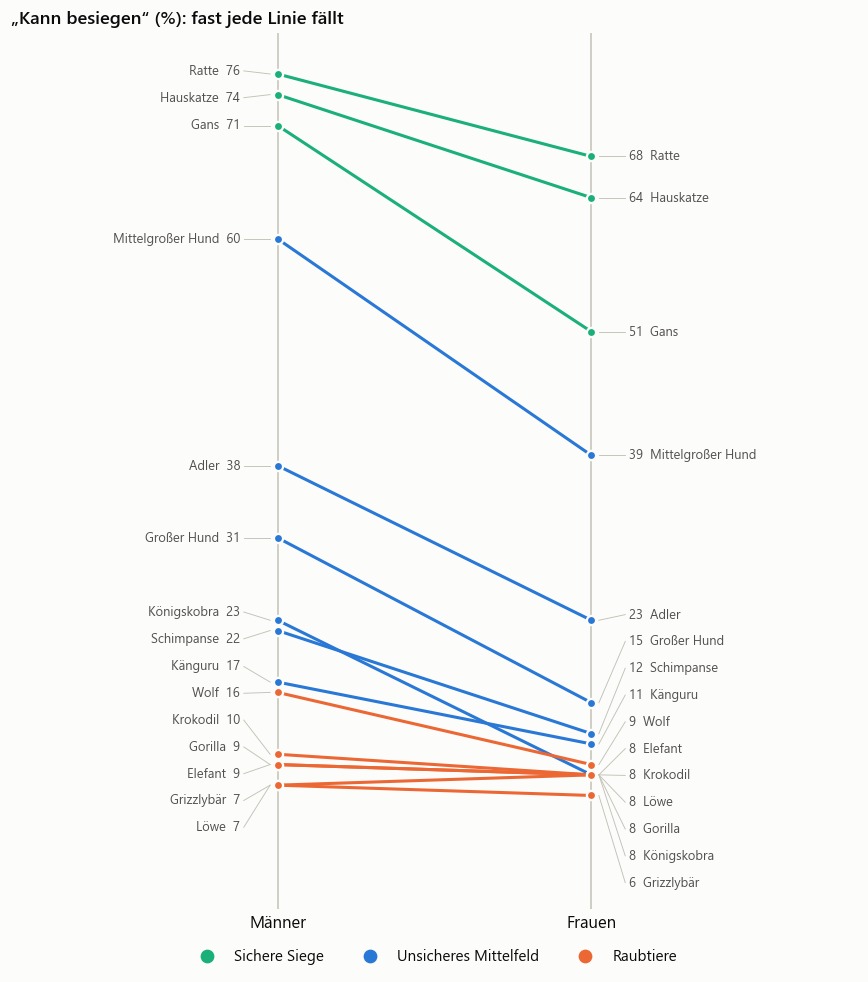

In [13]:
fig, ax = plt.subplots(figsize=(8, 9))
for a in ORDER:
    ax.plot([0, 1], [beat.loc[a, 'Male'], beat.loc[a, 'Female']], color=ARCH_COL[arch[a]],
            lw=2, marker='o', ms=6, mec=SURFACE, mew=1.5)
for side, g, ha, dx in [(0, 'Male', 'right', -0.12), (1, 'Female', 'left', 0.12)]:
    ys = beat[g].values
    for a, yv, yl in zip(ORDER, ys, spread(ys, 2.6)):
        lab = f'{DE[a]}  {yv}' if side == 0 else f'{yv}  {DE[a]}'
        ax.plot([side + dx * 0.2, side + dx * 0.9], [yv, yl], color=AXIS, lw=0.6)
        ax.text(side + dx, yl, lab, ha=ha, va='center', fontsize=8.5, color=INK2)
ax.set_xticks([0, 1], ['Männer', 'Frauen'], fontsize=11, color=INK)
ax.set_xlim(-0.85, 1.85); ax.set_ylim(-5, 80)
ax.set_yticks([]); ax.spines['left'].set_visible(False); ax.spines['bottom'].set_visible(False)
ax.tick_params(axis='x', length=0)
for x in (0, 1): ax.axvline(x, color=AXIS, lw=1, zorder=0)
ax.set_title('„Kann besiegen“ (%): fast jede Linie fällt')
arch_legend(ax, loc='upper center', bbox_to_anchor=(0.5, -0.03), ncol=3)
plt.tight_layout(); plt.show()

**Erkenntnis:** 14 von 15 Linien fallen von Männern zu Frauen, nur der Löwe steigt minimal
(7 → 8 %). Am steilsten fallen
die Linien im mittleren Bereich (Mittelgroßer Hund, Adler, Großer Hund) – genau dort, wo
die Antwort am wenigsten „offensichtlich“ ist.

## 12. Small Multiples: Alterstrend je Tier (Folie 70)

Ein eigenes kleines Liniendiagramm pro Tier statt 15 überlagerter Linien.
Damit Steigungen vergleichbar bleiben, hat jedes Panel **dieselbe y-Spannweite**
(nur um das Niveau des Tieres verschoben). Die gestrichelte Linie ist der Gesamtwert.

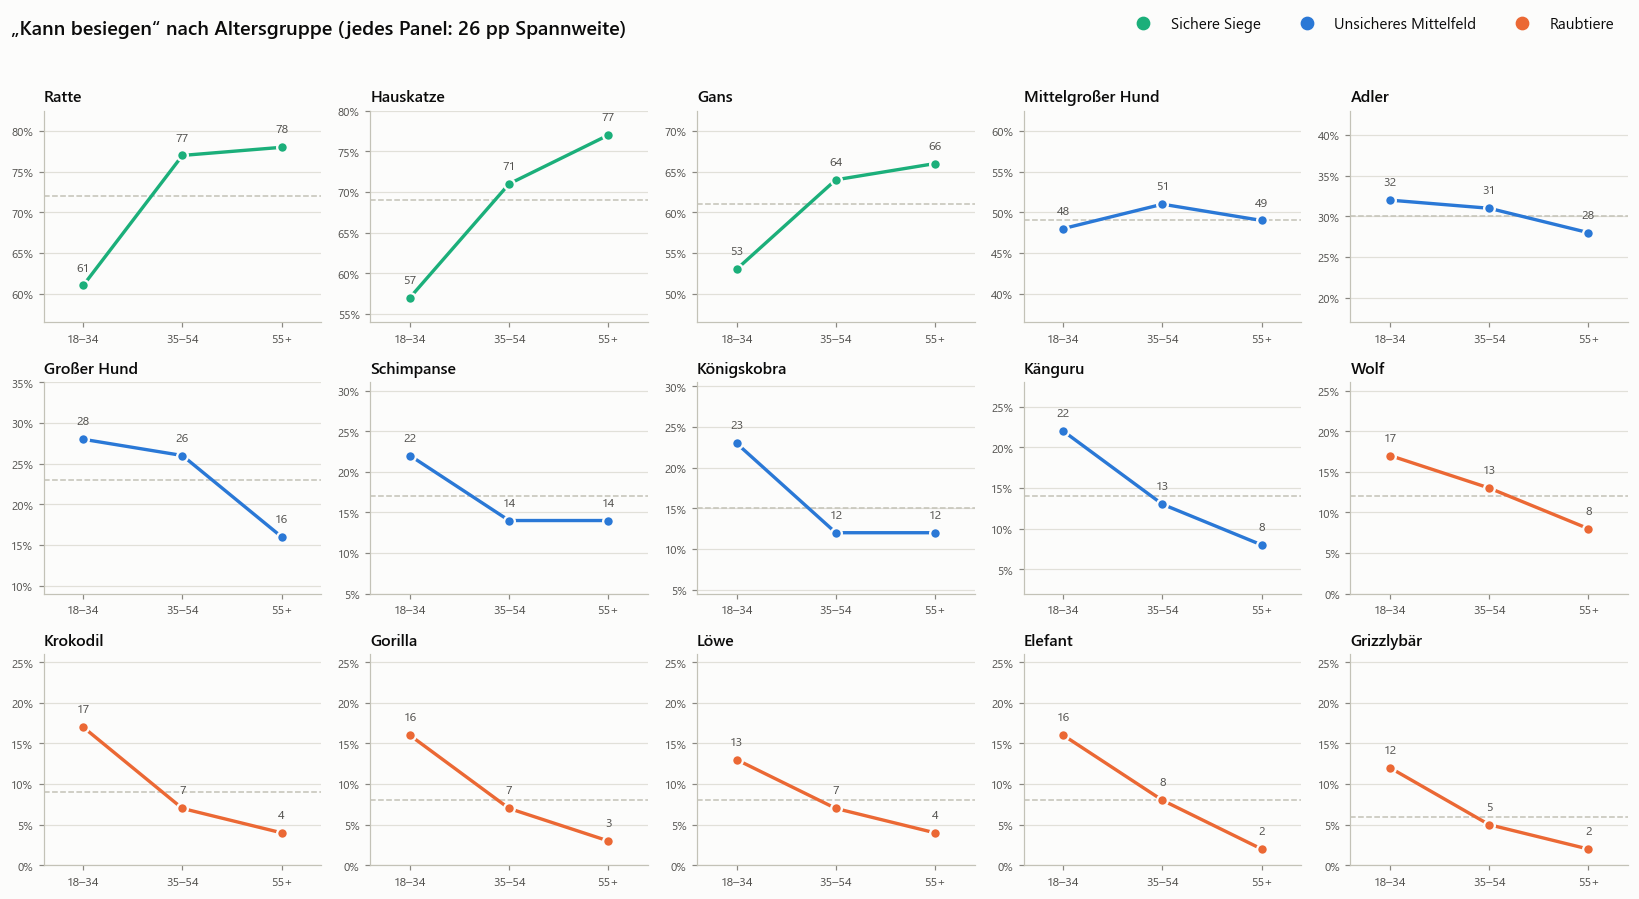

In [14]:
span = np.ceil((beat[AGE].max(axis=1) - beat[AGE].min(axis=1)).max() + 6)
fig, axes = plt.subplots(3, 5, figsize=(15, 8.2))
for ax, a in zip(axes.flat, ORDER):
    v = beat.loc[a, AGE].values; mid = (v.max() + v.min()) / 2
    ax.axhline(beat.loc[a, 'Total'], color=AXIS, ls='--', lw=1)
    ax.plot(range(3), v, color=ARCH_COL[arch[a]], lw=2.2, marker='o', ms=7, mec=SURFACE, mew=1.5)
    for xi, vi in enumerate(v):
        ax.text(xi, vi + span * 0.07, f'{vi}', ha='center', fontsize=8, color=INK2)
    ax.set_ylim(max(0, mid - span / 2) if mid - span / 2 < 0 else mid - span / 2, mid + span / 2)
    if mid - span / 2 < 0: ax.set_ylim(0, span)
    ax.set_xlim(-0.4, 2.4)
    ax.set_xticks(range(3), [GROUP_DE[g] for g in AGE], fontsize=8)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.tick_params(axis='y', labelsize=7.5)
    ax.grid(axis='y'); ax.set_title(DE[a], fontsize=10.5)
fig.suptitle(f'„Kann besiegen“ nach Altersgruppe (jedes Panel: {span:.0f} pp Spannweite)',
             x=0.01, ha='left', fontsize=13, weight='semibold')
arch_legend(fig, loc='upper right', ncol=3, bbox_to_anchor=(0.99, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

**Erkenntnis:** Durch die gleiche Spannweite sind die Steigungen direkt vergleichbar:
Bei den sicheren Siegen (grün) steigt die Zuversicht mit dem Alter deutlich, bei den
Raubtieren (orange) fällt sie. Der Kipppunkt liegt beim Mittelgroßen Hund (flach,
48 → 51 → 49 %); ab dem Adler fallen alle Linien. Der Alterseffekt hängt also vom Tier ab,
nicht nur vom Alter.

## Fazit & Technikwahl

| Technik | Eignung für diesen Datensatz |
|---|---|
| **Heatmap** (tabellenbasiert) | ⭐ Beste Gesamtübersicht über alle 150 Werte; Abweichungsversion zeigt Teilgruppeneffekte |
| **Parallele Koordinaten** | ⭐ Zeigt Profile + Rangstabilität; gemeinsame Skala möglich, da alle Achsen in % |
| **Slope Chart / Streudiagramm** | ⭐ Klarste Darstellung des Gender-Gaps |
| **Small Multiples / Mosaik** | ⭐ Zeigen den gegenläufigen Alterseffekt |
| SPLOM | Gut für Zusammenhänge zwischen Kennzahlen; bei 15 Punkten eher explorativ |
| Star Plots + PCA | Machen die drei Archetypen als Formen/Cluster sichtbar |
| Radar | Gute Gesamtform-Ansicht, aber Werte schwer exakt ablesbar |
| Parallel Sets | Nur 2 Achsen möglich (keine Kreuztabelle) |
| Grid-Kartogramm | Bestätigt, dass Region kaum Einfluss hat; nur 4 Regionen → geringe Auflösung |

**Nicht verwendet** wurden Netzwerk- (Folien 26–35) und Hierarchie-Techniken
(Treemap, Sunburst, Folien 36–43), da der Datensatz keine Beziehungen zwischen Objekten
und keine echte Hierarchie enthält, sowie Zeitreihen-Techniken (Horizon Chart, Stacked Area),
da es nur einen Erhebungszeitpunkt gibt. Die geordneten Altersgruppen erlauben aber,
Slope Chart und Small Multiples aus dem Temporal-Kapitel sinnvoll zu übertragen.

**Drei Kernaussagen:** (1) Die Gefährlichkeit des Tieres bestimmt die Antwort weit stärker
als jede Personengruppe. (2) Männer sind bei 14 von 15 Tieren zuversichtlicher, am stärksten bei Mittelgroßem
Hund und Gans (+21 bzw. +20 pp). (3) Der Alterseffekt ist gegenläufig: Ältere trauen sich mehr gegen kleine Tiere
zu, Jüngere mehr gegen gefährliche.